<a href="https://colab.research.google.com/github/miriamamin1213-ux/Ablation_studies/blob/main/HancockGPT2Tab3FoldCI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Device: cuda
Mounted at /content/drive
Rows with known target: 332
Class counts: {0: 191, 1: 141}
Train 215 {0: 123, 1: 92}
Validation 50 {0: 29, 1: 21}
Test 67 {0: 39, 1: 28}
Encoded input dimension: 19
Class weights: [0.87398374 1.16847826]


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 trainable parameters: 0
Other trainable parameters: 116354


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 50/500 | train=0.5863 | val=0.6013 | ROC-AUC=0.7365 | PR-AUC=0.6538 | balanced accuracy=0.7151
Epoch 100/500 | train=0.4848 | val=0.5845 | ROC-AUC=0.7496 | PR-AUC=0.7465 | balanced accuracy=0.7471
Epoch 150/500 | train=0.4495 | val=0.5636 | ROC-AUC=0.7709 | PR-AUC=0.7528 | balanced accuracy=0.7389
Epoch 200/500 | train=0.4240 | val=0.6416 | ROC-AUC=0.7611 | PR-AUC=0.7347 | balanced accuracy=0.7430
Epoch 250/500 | train=0.3491 | val=0.9603 | ROC-AUC=0.6954 | PR-AUC=0.6668 | balanced accuracy=0.6823
Epoch 300/500 | train=0.3286 | val=1.1056 | ROC-AUC=0.6708 | PR-AUC=0.6589 | balanced accuracy=0.6691
Epoch 350/500 | train=0.2710 | val=1.3958 | ROC-AUC=0.6773 | PR-AUC=0.6505 | balanced accuracy=0.6782
Epoch 400/500 | train=0.2525 | val=1.6540 | ROC-AUC=0.6379 | PR-AUC=0.5966 | balanced accuracy=0.6281
Epoch 450/500 | train=0.2430 | val=1.8618 | ROC-AUC=0.6149 | PR-AUC=0.5878 | balanced accuracy=0.6412
Epoch 500/500 | train=0.1826 | val=2.2067 | ROC-AUC=0.6232 | PR-AUC=0.5697 | balanc

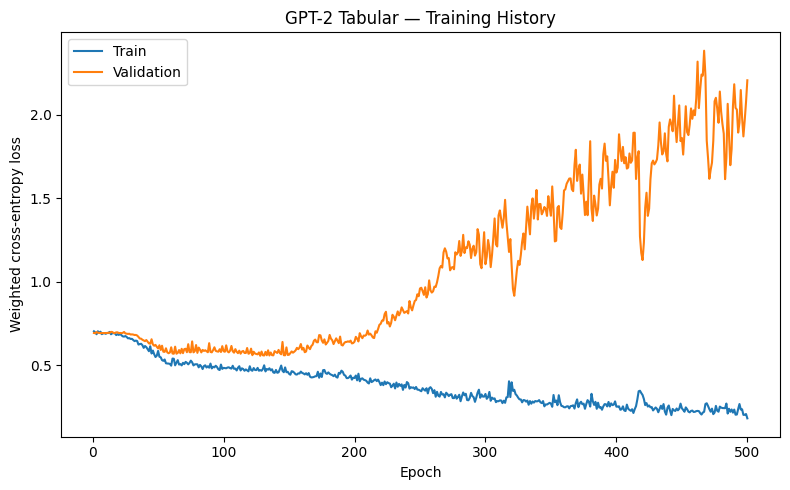


CHECKPOINT: best_val_loss | Epoch: 128
Checkpoint                      best_val_loss
Epoch                                     128
Threshold                            0.345092
Validation_Loss                      0.557112
Validation_ROC_AUC                   0.779146
Validation_PR_AUC                    0.754429
Validation_Balanced_Accuracy         0.773399
Balanced_Accuracy                    0.731227
F1                                   0.707692
ROC_AUC                              0.807692
PR_AUC                               0.782279
Confusion matrix:
 [[25 14]
 [ 5 23]]
              precision    recall  f1-score   support

HPV Negative     0.8333    0.6410    0.7246        39
HPV Positive     0.6216    0.8214    0.7077        28

    accuracy                         0.7164        67
   macro avg     0.7275    0.7312    0.7162        67
weighted avg     0.7449    0.7164    0.7176        67


CHECKPOINT: best_val_roc_auc | Epoch: 148
Checkpoint                      best_val_roc_a

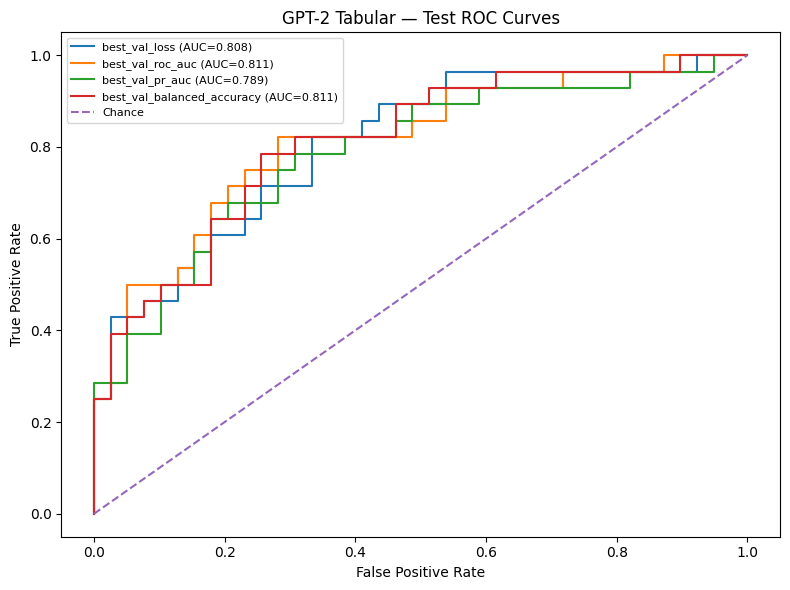

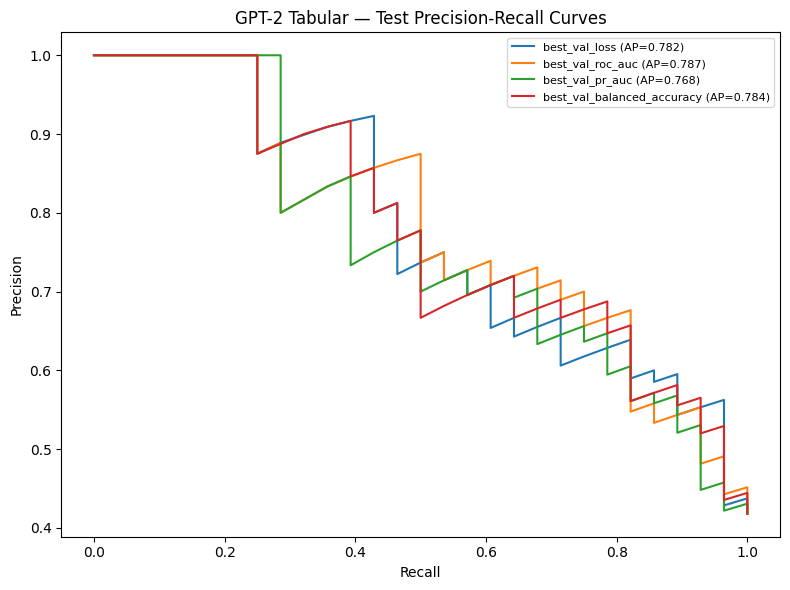

All results saved to: /content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results
Files: ['checkpoints', 'metrics_all_checkpoints.csv', 'run_summary.json', 'tabular_preprocessor.joblib', 'test_pr_curves.png', 'test_predictions_all_checkpoints.csv', 'test_roc_curves.png', 'training_history.csv', 'training_history.png']


In [1]:

# HANCOCK HPV — GPT-2 TABULAR CLASSIFIER
# Matched protocol: clinical narrative reference
# 65/15/20 stratified split | Seed 42 | Batch 64 | 500 epochs
# No SMOTE | Four validation-selected checkpoints

import os
import json
import random
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import joblib

from torch.utils.data import TensorDataset, DataLoader
from google.colab import drive
from transformers import GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
MAX_EPOCHS = 500
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1
MODEL_NAME = "openai-community/gpt2"


# ============================================================
# 1. REPRODUCIBILITY AND DEVICE
# ============================================================

def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    torch.use_deterministic_algorithms(True, warn_only=True)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

drive.mount("/content/drive")

BASE = "/content/drive/MyDrive"
OUT_DIR = os.path.join(BASE, "GPT2_Tabular_Hancock_Frozen_results")
CHECKPOINT_DIR = os.path.join(OUT_DIR, "checkpoints")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)


# ============================================================
# 2. LOAD AND PREPARE DATA
# ============================================================

def load_json_table(path):
    with open(path, encoding="utf-8") as f:
        obj = json.load(f)

    if isinstance(obj, list):
        return pd.DataFrame(obj)

    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if isinstance(obj.get(key), list):
                return pd.DataFrame(obj[key])
        return pd.DataFrame(obj)

    raise ValueError(f"Cannot read table: {path}")


clinical = load_json_table(
    os.path.join(BASE, "clinical_data.json")
)
pathology = load_json_table(
    os.path.join(BASE, "pathological_data.json")
)

if "patient_id" not in clinical.columns:
    raise KeyError("clinical_data.json must contain patient_id.")

if "patient_id" not in pathology.columns:
    raise KeyError("pathological_data.json must contain patient_id.")

df = clinical.merge(
    pathology,
    on="patient_id",
    how="left",
    suffixes=("", "_path")
)

target_col = next(
    (
        c for c in [
            "hpv_association_p16",
            "hpv_association_p16_path"
        ]
        if c in df.columns
    ),
    None
)

if target_col is None:
    raise KeyError("Could not find hpv_association_p16 target.")

feature_candidates = {
    "age_at_initial_diagnosis": [
        "age_at_initial_diagnosis"
    ],
    "sex": ["sex"],
    "smoking_status": ["smoking_status"],
    "primary_tumor_site": ["primary_tumor_site"],
    "primarily_metastasis": ["primarily_metastasis"],
    "pN_stage": [
        "pN_stage",
        "pN_stage_path",
        "pathological_N_stage",
        "pathological_n_stage"
    ]
}

rename_map = {}

for feature, candidates in feature_candidates.items():
    found = next(
        (c for c in candidates if c in df.columns),
        None
    )

    if found is None:
        raise KeyError(
            f"Missing predictor {feature}; checked {candidates}"
        )

    if found != feature:
        rename_map[found] = feature

df = df.rename(columns=rename_map)
features = list(feature_candidates)


def normalize_label(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower()

    if value in {"negative", "neg", "0", "false", "no"}:
        return 0

    if value in {"positive", "pos", "1", "true", "yes"}:
        return 1

    try:
        number = float(value)
        if number in (0.0, 1.0):
            return int(number)
    except (ValueError, TypeError):
        pass

    return np.nan


df["HPV_Label"] = df[target_col].map(normalize_label)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

df = df[
    ["patient_id"] + features + ["HPV_Label"]
].copy()

print("Rows with known target:", len(df))
print(
    "Class counts:",
    df["HPV_Label"].value_counts().sort_index().to_dict()
)


# ============================================================
# 3. STRATIFIED 65/15/20 TRAIN/VALIDATION/TEST SPLIT
# ============================================================

train_val, test = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["HPV_Label"]
)

train, val = train_test_split(
    train_val,
    test_size=0.1875,
    random_state=SEED,
    stratify=train_val["HPV_Label"]
)

train, val, test = [
    part.reset_index(drop=True)
    for part in (train, val, test)
]

for name, part in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    print(
        name,
        len(part),
        part["HPV_Label"].value_counts().sort_index().to_dict()
    )

X_train_df, X_val_df, X_test_df = [
    part[features].copy()
    for part in (train, val, test)
]

y_train, y_val, y_test = [
    part["HPV_Label"].to_numpy(dtype=np.int64)
    for part in (train, val, test)
]


# ============================================================
# 4. IMPUTATION AND ONE-HOT ENCODING
# ============================================================

numeric_features = ["age_at_initial_diagnosis"]
categorical_features = [
    c for c in features if c not in numeric_features
]

for frame in (X_train_df, X_val_df, X_test_df):
    frame["age_at_initial_diagnosis"] = pd.to_numeric(
        frame["age_at_initial_diagnosis"],
        errors="coerce"
    )

age_median = X_train_df[
    "age_at_initial_diagnosis"
].median()

if pd.isna(age_median):
    age_median = 0.0

for frame in (X_train_df, X_val_df, X_test_df):
    frame["age_at_initial_diagnosis"] = (
        frame["age_at_initial_diagnosis"].fillna(age_median)
    )

for col in categorical_features:
    modes = X_train_df[col].dropna().astype(str).mode()
    fill_value = modes.iloc[0] if not modes.empty else "Unknown"

    for frame in (X_train_df, X_val_df, X_test_df):
        frame[col] = frame[col].fillna(fill_value)
        frame[col] = frame[col].astype(str).replace({
            "": "Unknown",
            "nan": "Unknown",
            "None": "Unknown"
        })

try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", encoder, categorical_features)
])

X_train = preprocessor.fit_transform(
    X_train_df
).astype(np.float32)

X_val = preprocessor.transform(
    X_val_df
).astype(np.float32)

X_test = preprocessor.transform(
    X_test_df
).astype(np.float32)

print("Encoded input dimension:", X_train.shape[1])


# ============================================================
# 5. CLASS WEIGHTS — NO SMOTE
# ============================================================

counts = np.bincount(y_train, minlength=2)

if np.any(counts == 0):
    raise ValueError(
        "Both classes must be present in training data."
    )

weights = len(y_train) / (2.0 * counts)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device
)

print("Class weights:", weights)

train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

X_val_t = torch.tensor(
    X_val, dtype=torch.float32, device=device
)
y_val_t = torch.tensor(
    y_val, dtype=torch.long, device=device
)
X_test_t = torch.tensor(
    X_test, dtype=torch.float32, device=device
)


# ============================================================
# 6. TABULAR GPT-2 ARCHITECTURE — PRESERVED
# ============================================================

class GPT2TabularClassifier(nn.Module):
    def __init__(self, n_features, dropout=0.1):
        super().__init__()

        self.gpt2 = GPT2Model.from_pretrained(MODEL_NAME)

        # Freeze all GPT-2 backbone parameters
        for param in self.gpt2.parameters():
            param.requires_grad = False

        hidden = self.gpt2.config.hidden_size
        self.feature_projection = nn.Linear(1, hidden)

        self.feature_embedding = nn.Parameter(
            torch.zeros(1, n_features, hidden)
        )
        nn.init.normal_(
            self.feature_embedding,
            mean=0.0,
            std=0.02
        )

        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden),
            nn.Dropout(dropout),
            nn.Linear(hidden, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        tokens = self.feature_projection(x.unsqueeze(-1))
        tokens = tokens + self.feature_embedding

        hidden = self.gpt2(
            inputs_embeds=tokens
        ).last_hidden_state

        return self.classifier(hidden.mean(dim=1))


model = GPT2TabularClassifier(
    X_train.shape[1],
    DROPOUT
).to(device)
# VERIFY GPT-2 BACKBONE IS FROZEN
gpt2_trainable = sum(
    p.numel() for p in model.gpt2.parameters()
    if p.requires_grad
)

other_trainable = sum(
    p.numel() for name, p in model.named_parameters()
    if not name.startswith("gpt2.") and p.requires_grad
)

print("GPT-2 trainable parameters:", gpt2_trainable)
print("Other trainable parameters:", other_trainable)

assert gpt2_trainable == 0, "GPT-2 is NOT frozen!"
assert other_trainable > 0, "Tabular/classifier layers are NOT trainable!"



# Match clinical narrative weighted-loss calculation
def weighted_classification_loss(logits, labels):
    losses = nn.functional.cross_entropy(
        logits,
        labels,
        reduction="none"
    )
    return (losses * class_weights[labels]).mean()


def evaluate_loss():
    model.eval()

    with torch.no_grad():
        return weighted_classification_loss(
            model(X_val_t),
            y_val_t
        ).item()


optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


def predict_probabilities(X_tensor):
    model.eval()

    with torch.no_grad():
        return torch.softmax(
            model(X_tensor),
            dim=1
        )[:, 1].cpu().numpy()


# ============================================================
# 7. VALIDATION THRESHOLD AND METRICS
# ============================================================

def select_threshold(y_true, probabilities):
    thresholds = np.unique(
        np.concatenate(([0.0], probabilities, [1.0]))
    )

    results = [
        (
            float(t),
            balanced_accuracy_score(
                y_true,
                (probabilities >= t).astype(int)
            )
        )
        for t in thresholds
    ]

    # Maximise balanced accuracy; ties closest to 0.5
    return max(
        results,
        key=lambda x: (x[1], -abs(x[0] - 0.5))
    )


def validation_metrics():
    p = predict_probabilities(X_val_t)
    threshold, bal_acc = select_threshold(y_val, p)

    roc_auc = (
        roc_auc_score(y_val, p)
        if len(np.unique(y_val)) == 2
        else np.nan
    )

    return {
        "threshold": float(threshold),
        "balanced_accuracy": float(bal_acc),
        "roc_auc": float(roc_auc),
        "pr_auc": float(average_precision_score(y_val, p))
    }


checkpoint_specs = {
    "best_val_loss": (
        "gpt2_best_val_loss.pt", "min"
    ),
    "best_val_roc_auc": (
        "gpt2_best_val_roc_auc.pt", "max"
    ),
    "best_val_pr_auc": (
        "gpt2_best_val_pr_auc.pt", "max"
    ),
    "best_val_balanced_accuracy": (
        "gpt2_best_val_balanced_accuracy.pt", "max"
    )
}

best_values = {
    "best_val_loss": float("inf"),
    "best_val_roc_auc": -float("inf"),
    "best_val_pr_auc": -float("inf"),
    "best_val_balanced_accuracy": -float("inf")
}

best_epochs = {}
history = []


# ============================================================
# 8. TRAIN — 500 EPOCHS
# ============================================================

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    model.gpt2.eval()
    loss_sum = 0.0
    n_seen = 0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        loss = weighted_classification_loss(
            model(xb), yb
        )

        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * len(yb)
        n_seen += len(yb)

    train_loss = loss_sum / max(n_seen, 1)
    val_loss = evaluate_loss()
    vm = validation_metrics()

    history.append({
        "epoch": int(epoch),
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "val_roc_auc": float(vm["roc_auc"]),
        "val_pr_auc": float(vm["pr_auc"]),
        "val_balanced_accuracy": float(vm["balanced_accuracy"]),
        "val_threshold": float(vm["threshold"])
    })

    scores = {
        "best_val_loss": val_loss,
        "best_val_roc_auc": vm["roc_auc"],
        "best_val_pr_auc": vm["pr_auc"],
        "best_val_balanced_accuracy": vm["balanced_accuracy"]
    }

    for key, score in scores.items():
        direction = checkpoint_specs[key][1]

        improved = (
            score < best_values[key]
            if direction == "min"
            else score > best_values[key]
        )

        if not np.isfinite(score) or not improved:
            continue

        best_values[key] = float(score)
        best_epochs[key] = int(epoch)

        # Store only standard Python scalar metadata.
        checkpoint_data = {
            "epoch": int(epoch),
            "model_state_dict": copy.deepcopy(model.state_dict()),
            "validation_loss": float(val_loss),
            "validation_roc_auc": float(vm["roc_auc"]),
            "validation_pr_auc": float(vm["pr_auc"]),
            "validation_balanced_accuracy": float(
                vm["balanced_accuracy"]
            ),
            "validation_threshold": float(vm["threshold"])
        }

        torch.save(
            checkpoint_data,
            os.path.join(
                CHECKPOINT_DIR,
                checkpoint_specs[key][0]
            )
        )

    if epoch % 50 == 0:
        print(
            f"Epoch {epoch}/{MAX_EPOCHS} | "
            f"train={train_loss:.4f} | "
            f"val={val_loss:.4f} | "
            f"ROC-AUC={vm['roc_auc']:.4f} | "
            f"PR-AUC={vm['pr_auc']:.4f} | "
            f"balanced accuracy={vm['balanced_accuracy']:.4f}"
        )

if len(history) != MAX_EPOCHS:
    raise RuntimeError(
        f"Expected {MAX_EPOCHS} epochs; ran {len(history)}."
    )

history_df = pd.DataFrame(history)

history_df.to_csv(
    os.path.join(OUT_DIR, "training_history.csv"),
    index=False
)

print("Best checkpoint epochs:", best_epochs)

plt.figure(figsize=(8, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Train"
)
plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation"
)
plt.xlabel("Epoch")
plt.ylabel("Weighted cross-entropy loss")
plt.title("GPT-2 Tabular — Training History")
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "training_history.png"),
    dpi=150
)
plt.show()


# ============================================================
# 9. TEST EACH SELECTED CHECKPOINT
# ============================================================

all_metrics = []
all_predictions = []
test_probabilities = {}

for name, (filename, _) in checkpoint_specs.items():
    checkpoint_path = os.path.join(
        CHECKPOINT_DIR, filename
    )

    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(
            f"Checkpoint not found: {checkpoint_path}. "
            "Run the training section first, or check Drive."
        )

    # FIX FOR PYTORCH 2.6+:
    # Use weights_only=False only for trusted checkpoints
    # generated by this notebook.
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    val_prob = predict_probabilities(X_val_t)
    test_prob = predict_probabilities(X_test_t)
    test_probabilities[name] = test_prob

    # Select threshold from validation data only.
    threshold, val_bal_acc = select_threshold(
        y_val, val_prob
    )

    test_pred = (test_prob >= threshold).astype(int)

    test_roc_auc = (
        roc_auc_score(y_test, test_prob)
        if len(np.unique(y_test)) == 2
        else np.nan
    )

    test_pr_auc = average_precision_score(
        y_test, test_prob
    )

    metrics = {
        "Checkpoint": name,
        "Epoch": int(checkpoint["epoch"]),
        "Threshold": float(threshold),
        "Validation_Loss": float(checkpoint["validation_loss"]),
        "Validation_ROC_AUC": float(checkpoint["validation_roc_auc"]),
        "Validation_PR_AUC": float(checkpoint["validation_pr_auc"]),
        "Validation_Balanced_Accuracy": float(val_bal_acc),
        "Balanced_Accuracy": float(
            balanced_accuracy_score(y_test, test_pred)
        ),
        "F1": float(
            f1_score(y_test, test_pred, zero_division=0)
        ),
        "ROC_AUC": float(test_roc_auc),
        "PR_AUC": float(test_pr_auc)
    }

    all_metrics.append(metrics)

    all_predictions.append(pd.DataFrame({
        "patient_id": test["patient_id"].to_numpy(),
        "y_true": y_test,
        "probability_positive": test_prob,
        "prediction": test_pred,
        "checkpoint": name,
        "epoch": int(checkpoint["epoch"]),
        "threshold": float(threshold)
    }))

    print("\n", "=" * 55)
    print("CHECKPOINT:", name, "| Epoch:", checkpoint["epoch"])
    print(pd.Series(metrics).to_string())

    print(
        "Confusion matrix:\n",
        confusion_matrix(y_test, test_pred, labels=[0, 1])
    )

    print(classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"],
        digits=4,
        zero_division=0
    ))

pd.DataFrame(all_metrics).to_csv(
    os.path.join(OUT_DIR, "metrics_all_checkpoints.csv"),
    index=False
)

pd.concat(
    all_predictions,
    ignore_index=True
).to_csv(
    os.path.join(
        OUT_DIR,
        "test_predictions_all_checkpoints.csv"
    ),
    index=False
)


# ============================================================
# 10. TEST ROC CURVES
# ============================================================

plt.figure(figsize=(8, 6))

for name, p in test_probabilities.items():
    if len(np.unique(y_test)) < 2:
        continue

    fpr, tpr, _ = roc_curve(y_test, p)
    auc = roc_auc_score(y_test, p)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("GPT-2 Tabular — Test ROC Curves")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "test_roc_curves.png"),
    dpi=150
)
plt.show()


# ============================================================
# 11. TEST PRECISION-RECALL CURVES
# ============================================================

plt.figure(figsize=(8, 6))

for name, p in test_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_test, p)
    ap = average_precision_score(y_test, p)

    plt.plot(
        recall, precision,
        label=f"{name} (AP={ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("GPT-2 Tabular — Test Precision-Recall Curves")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "test_pr_curves.png"),
    dpi=150
)
plt.show()


# ============================================================
# 12. SAVE PREPROCESSOR AND RUN SUMMARY
# ============================================================

joblib.dump(
    preprocessor,
    os.path.join(OUT_DIR, "tabular_preprocessor.joblib")
)

summary = {
    "seed": SEED,
    "model_name": MODEL_NAME,
    "epochs": MAX_EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "dropout": DROPOUT,
    "original_predictors": features,
    "encoded_feature_count": int(X_train.shape[1]),
    "train_rows": int(len(train)),
    "validation_rows": int(len(val)),
    "test_rows": int(len(test)),
    "smote": False,
    "gradient_clipping": False,
    "gpt2_fine_tuned": True,
    "class_weights": [
        float(w) for w in class_weights.detach().cpu().tolist()
    ],
    "checkpoint_selection": (
        "Best validation loss, ROC-AUC, PR-AUC "
        "and balanced accuracy"
    ),
    "threshold_selection": (
        "Maximise validation balanced accuracy over unique "
        "scores plus 0 and 1; ties closest to 0.5"
    ),
    "loss": (
        "Mean per-example cross-entropy multiplied "
        "by target-class weight"
    ),
    "best_epochs": {
        k: int(v) for k, v in best_epochs.items()
    }
}

with open(
    os.path.join(OUT_DIR, "run_summary.json"),
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, indent=2)

print("All results saved to:", OUT_DIR)
print("Files:", sorted(os.listdir(OUT_DIR)))


In [2]:
import os
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

file_path = (
    "/content/drive/MyDrive/"
    "GPT2_Tabular_Hancock_Frozen_results/"
    "test_predictions_all_checkpoints.csv"
)

# 1. Check that the file exists
print("File exists:", os.path.exists(file_path))

if not os.path.exists(file_path):
    raise FileNotFoundError(file_path)

# 2. Load the saved predictions
pred = pd.read_csv(file_path)

print("\nColumns:")
print(pred.columns.tolist())

print("\nTotal rows:", len(pred))

# 3. Check each checkpoint
for name, group in pred.groupby("checkpoint"):

    print("\n------------------------------")
    print("Checkpoint:", name)
    print("Number of test patients:", len(group))
    print("Unique patients:", group["patient_id"].nunique())
    print("Missing true labels:", group["y_true"].isna().sum())
    print("Missing probabilities:", group["probability_positive"].isna().sum())

    y_true = group["y_true"].astype(int)
    scores = group["probability_positive"]

    print("ROC-AUC:", round(roc_auc_score(y_true, scores), 4))
    print("PR-AUC:", round(average_precision_score(y_true, scores), 4))

# 4. Check the expected four checkpoints
print("\nCheckpoint names:")
print(pred["checkpoint"].unique())

File exists: True

Columns:
['patient_id', 'y_true', 'probability_positive', 'prediction', 'checkpoint', 'epoch', 'threshold']

Total rows: 268

------------------------------
Checkpoint: best_val_balanced_accuracy
Number of test patients: 67
Unique patients: 67
Missing true labels: 0
Missing probabilities: 0
ROC-AUC: 0.8114
PR-AUC: 0.7843

------------------------------
Checkpoint: best_val_loss
Number of test patients: 67
Unique patients: 67
Missing true labels: 0
Missing probabilities: 0
ROC-AUC: 0.8077
PR-AUC: 0.7823

------------------------------
Checkpoint: best_val_pr_auc
Number of test patients: 67
Unique patients: 67
Missing true labels: 0
Missing probabilities: 0
ROC-AUC: 0.7894
PR-AUC: 0.7675

------------------------------
Checkpoint: best_val_roc_auc
Number of test patients: 67
Unique patients: 67
Missing true labels: 0
Missing probabilities: 0
ROC-AUC: 0.8114
PR-AUC: 0.7865

Checkpoint names:
['best_val_loss' 'best_val_roc_auc' 'best_val_pr_auc'
 'best_val_balanced_accur

In [3]:
import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix
)
from sklearn.utils import resample

# =====================================================
# 1. FILE PATHS
# =====================================================

OUT_DIR = (
    "/content/drive/MyDrive/"
    "GPT2_Tabular_Hancock_Frozen_results"
)

PREDICTION_FILE = os.path.join(
    OUT_DIR,
    "test_predictions_all_checkpoints.csv"
)

OUTPUT_FILE = os.path.join(
    OUT_DIR,
    "HANCOCK_GPT2_Tabular_Frozen_confidence_intervals.csv"
)

# =====================================================
# 2. LOAD SELECTED CHECKPOINT
# =====================================================

df = pd.read_csv(PREDICTION_FILE)

selected = df[
    df["checkpoint"] == "best_val_roc_auc"
].copy()

assert len(selected) == 67, (
    f"Expected 67 test patients, found {len(selected)}"
)

assert selected["patient_id"].nunique() == 67
assert selected["epoch"].nunique() == 1
assert int(selected["epoch"].iloc[0]) == 148

y_true = selected["y_true"].astype(int).to_numpy()
y_prob = selected["probability_positive"].astype(float).to_numpy()
threshold = float(selected["threshold"].iloc[0])

y_pred = (y_prob >= threshold).astype(int)

print("Selected checkpoint: best_val_roc_auc")
print("Selected epoch:", int(selected["epoch"].iloc[0]))
print("Test patients:", len(y_true))
print("Threshold:", threshold)

# =====================================================
# 3. METRIC CALCULATION
# =====================================================

def calculate_metrics(y, probabilities, predictions):

    tn, fp, fn, tp = confusion_matrix(
        y, predictions, labels=[0, 1]
    ).ravel()

    return {
        "ROC_AUC": roc_auc_score(y, probabilities),
        "PR_AUC": average_precision_score(y, probabilities),
        "Balanced_Accuracy": balanced_accuracy_score(y, predictions),
        "Sensitivity": recall_score(
            y, predictions, pos_label=1, zero_division=0
        ),
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "F1_Score": f1_score(
            y, predictions, pos_label=1, zero_division=0
        )
    }

original_metrics = calculate_metrics(
    y_true, y_prob, y_pred
)

# =====================================================
# 4. STRATIFIED BOOTSTRAP
# =====================================================

N_BOOTSTRAPS = 5000
RANDOM_SEED = 42

rng = np.random.default_rng(RANDOM_SEED)

positive_indices = np.where(y_true == 1)[0]
negative_indices = np.where(y_true == 0)[0]

bootstrap_results = {
    metric: [] for metric in original_metrics
}

for i in range(N_BOOTSTRAPS):

    # Resample positive and negative patients separately
    boot_pos = rng.choice(
        positive_indices,
        size=len(positive_indices),
        replace=True
    )

    boot_neg = rng.choice(
        negative_indices,
        size=len(negative_indices),
        replace=True
    )

    boot_indices = np.concatenate([boot_pos, boot_neg])

    boot_y = y_true[boot_indices]
    boot_prob = y_prob[boot_indices]
    boot_pred = (boot_prob >= threshold).astype(int)

    metrics = calculate_metrics(
        boot_y, boot_prob, boot_pred
    )

    for metric, value in metrics.items():
        bootstrap_results[metric].append(value)

# =====================================================
# 5. CALCULATE 95% CONFIDENCE INTERVALS
# =====================================================

results = []

for metric, point_estimate in original_metrics.items():

    values = np.asarray(bootstrap_results[metric])
    values = values[np.isfinite(values)]

    lower = np.percentile(values, 2.5)
    upper = np.percentile(values, 97.5)

    results.append({
        "Model": "GPT2_Tabular_Frozen",
        "Checkpoint": "best_val_roc_auc",
        "Epoch": 148,
        "Metric": metric,
        "Estimate": point_estimate,
        "CI_95_Lower": lower,
        "CI_95_Upper": upper,
        "Bootstrap_Replicates": len(values)
    })

ci_df = pd.DataFrame(results)

# =====================================================
# 6. SAVE TO GOOGLE DRIVE
# =====================================================

ci_df.to_csv(OUTPUT_FILE, index=False)

print("\nCONFIDENCE INTERVAL RESULTS")
display(ci_df.round(4))

print("\nSaved successfully to:")
print(OUTPUT_FILE)

Selected checkpoint: best_val_roc_auc
Selected epoch: 148
Test patients: 67
Threshold: 0.257873922586441

CONFIDENCE INTERVAL RESULTS


,Model,Checkpoint,Epoch,Metric,Estimate,CI_95_Lower,CI_95_Upper,Bootstrap_Replicates
0,GPT2_Tabular_Frozen,best_val_roc_auc,148,ROC_AUC,0.8114,0.6941,0.9084,5000
1,GPT2_Tabular_Frozen,best_val_roc_auc,148,PR_AUC,0.7865,0.6704,0.8969,5000
2,GPT2_Tabular_Frozen,best_val_roc_auc,148,Balanced_Accuracy,0.7697,0.6648,0.8668,5000
3,GPT2_Tabular_Frozen,best_val_roc_auc,148,Sensitivity,0.8214,0.6786,0.9643,5000
4,GPT2_Tabular_Frozen,best_val_roc_auc,148,Specificity,0.7179,0.5641,0.8462,5000
5,GPT2_Tabular_Frozen,best_val_roc_auc,148,F1_Score,0.7419,0.6316,0.8438,5000



Saved successfully to:
/content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_results/HANCOCK_GPT2_Tabular_Frozen_confidence_intervals.csv


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
Output folder: /content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_3Fold_CV

Full Hancock dataset:
Patients: 332
Class counts: {0: 191, 1: 141}

Features:
['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']

3-fold split verification:

Fold 1
Training: 221 Class counts: [127, 94]
Validation: 111 Class counts: [64, 47]

Fold 2
Training: 221 Class counts: [127, 94]
Validation: 111 Class counts: [64, 47]

Fold 3
Training: 222 Class counts: [128, 94]
Validation: 110 Class counts: [63, 47]

STARTING FOLD 1/3
Training patients: 221
Validation patients: 111
Encoded feature dimension: 18
Training class weights: [0.87007874 1.17553191]


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 trainable parameters: 0
Other trainable parameters: 115586
Fold 1 | Epoch 50/500 | Train loss=0.5437 | Val loss=0.6270 | ROC-AUC=0.7264 | PR-AUC=0.7171 | BA=0.6991
Fold 1 | Epoch 100/500 | Train loss=0.4109 | Val loss=0.6670 | ROC-AUC=0.7061 | PR-AUC=0.7066 | BA=0.6709
Fold 1 | Epoch 150/500 | Train loss=0.4019 | Val loss=0.7567 | ROC-AUC=0.6991 | PR-AUC=0.6953 | BA=0.6820
Fold 1 | Epoch 200/500 | Train loss=0.3324 | Val loss=0.8661 | ROC-AUC=0.6971 | PR-AUC=0.7028 | BA=0.6787
Fold 1 | Epoch 250/500 | Train loss=0.3314 | Val loss=0.9205 | ROC-AUC=0.6759 | PR-AUC=0.6843 | BA=0.6735
Fold 1 | Epoch 300/500 | Train loss=0.2596 | Val loss=1.4433 | ROC-AUC=0.6559 | PR-AUC=0.6846 | BA=0.6730
Fold 1 | Epoch 350/500 | Train loss=0.2171 | Val loss=1.5592 | ROC-AUC=0.6609 | PR-AUC=0.6877 | BA=0.6730
Fold 1 | Epoch 400/500 | Train loss=0.1884 | Val loss=1.8804 | ROC-AUC=0.6413 | PR-AUC=0.6708 | BA=0.6652
Fold 1 | Epoch 450/500 | Train loss=0.1510 | Val loss=2.1600 | ROC-AUC=0.6373 | PR-AUC=0

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 trainable parameters: 0
Other trainable parameters: 116354
Fold 2 | Epoch 50/500 | Train loss=0.5120 | Val loss=0.5779 | ROC-AUC=0.7763 | PR-AUC=0.7388 | BA=0.7467
Fold 2 | Epoch 100/500 | Train loss=0.4817 | Val loss=0.5871 | ROC-AUC=0.7763 | PR-AUC=0.7563 | BA=0.7282
Fold 2 | Epoch 150/500 | Train loss=0.4366 | Val loss=0.5825 | ROC-AUC=0.7756 | PR-AUC=0.7577 | BA=0.7232
Fold 2 | Epoch 200/500 | Train loss=0.4232 | Val loss=0.5648 | ROC-AUC=0.7896 | PR-AUC=0.7924 | BA=0.7432
Fold 2 | Epoch 250/500 | Train loss=0.4038 | Val loss=0.6025 | ROC-AUC=0.7912 | PR-AUC=0.7818 | BA=0.7276
Fold 2 | Epoch 300/500 | Train loss=0.3741 | Val loss=0.6159 | ROC-AUC=0.7906 | PR-AUC=0.7815 | BA=0.7460
Fold 2 | Epoch 350/500 | Train loss=0.3361 | Val loss=0.6444 | ROC-AUC=0.7899 | PR-AUC=0.7693 | BA=0.7304
Fold 2 | Epoch 400/500 | Train loss=0.3365 | Val loss=0.7199 | ROC-AUC=0.7929 | PR-AUC=0.7678 | BA=0.7389
Fold 2 | Epoch 450/500 | Train loss=0.3310 | Val loss=0.7510 | ROC-AUC=0.7606 | PR-AUC=0

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 trainable parameters: 0
Other trainable parameters: 116354
Fold 3 | Epoch 50/500 | Train loss=0.5141 | Val loss=0.5841 | ROC-AUC=0.7472 | PR-AUC=0.7569 | BA=0.7048
Fold 3 | Epoch 100/500 | Train loss=0.4214 | Val loss=0.6773 | ROC-AUC=0.7070 | PR-AUC=0.7307 | BA=0.6890
Fold 3 | Epoch 150/500 | Train loss=0.4421 | Val loss=0.8210 | ROC-AUC=0.6662 | PR-AUC=0.6950 | BA=0.6756
Fold 3 | Epoch 200/500 | Train loss=0.3571 | Val loss=0.9083 | ROC-AUC=0.6513 | PR-AUC=0.6725 | BA=0.6677
Fold 3 | Epoch 250/500 | Train loss=0.3396 | Val loss=1.0757 | ROC-AUC=0.6439 | PR-AUC=0.6657 | BA=0.6597
Fold 3 | Epoch 300/500 | Train loss=0.3160 | Val loss=1.1931 | ROC-AUC=0.6293 | PR-AUC=0.6640 | BA=0.6570
Fold 3 | Epoch 350/500 | Train loss=0.2737 | Val loss=1.2488 | ROC-AUC=0.6348 | PR-AUC=0.6546 | BA=0.6650
Fold 3 | Epoch 400/500 | Train loss=0.2840 | Val loss=1.3698 | ROC-AUC=0.6344 | PR-AUC=0.6808 | BA=0.6756
Fold 3 | Epoch 450/500 | Train loss=0.2577 | Val loss=1.4334 | ROC-AUC=0.6415 | PR-AUC=0

,Fold,Training_N,Validation_N,Selected_Epoch,Threshold,Validation_Loss,ROC_AUC,PR_AUC,Balanced_Accuracy,Sensitivity,Specificity,F1,TN,FP,FN,TP
0,1,221,111,58,0.5744,0.6236,0.7284,0.7190,0.6991,0.6170,0.7812,0.6444,50,14,18,29
1,2,221,111,252,0.8106,0.6213,0.8025,0.7982,0.7460,0.6170,0.8750,0.6905,56,8,18,29
2,3,222,110,33,0.4969,0.5780,0.7827,0.7516,0.7398,0.6383,0.8413,0.6897,53,10,17,30



MEAN AND STANDARD DEVIATION


,Metric,Mean,Standard_Deviation
0,ROC_AUC,0.7712,0.0384
1,PR_AUC,0.7563,0.0398
2,Balanced_Accuracy,0.7283,0.0255
3,Sensitivity,0.6241,0.0123
4,Specificity,0.8325,0.0475
5,F1,0.6749,0.0263


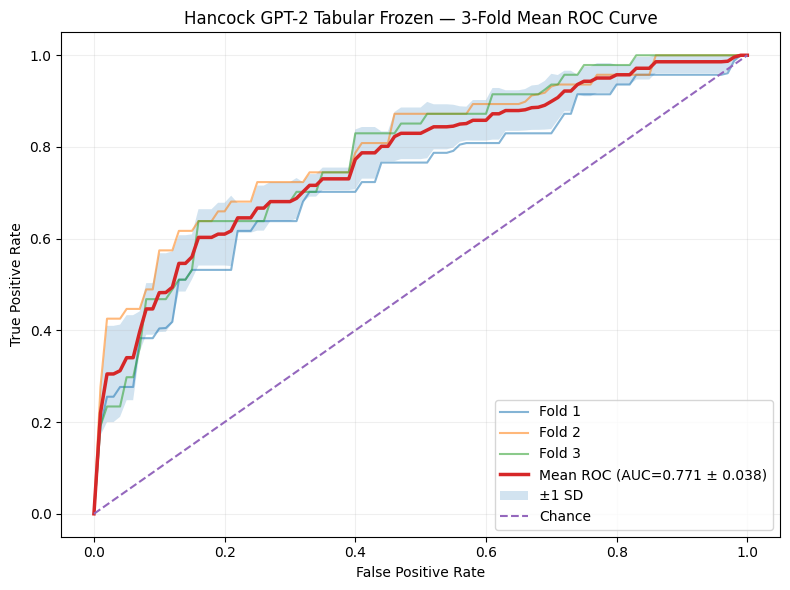

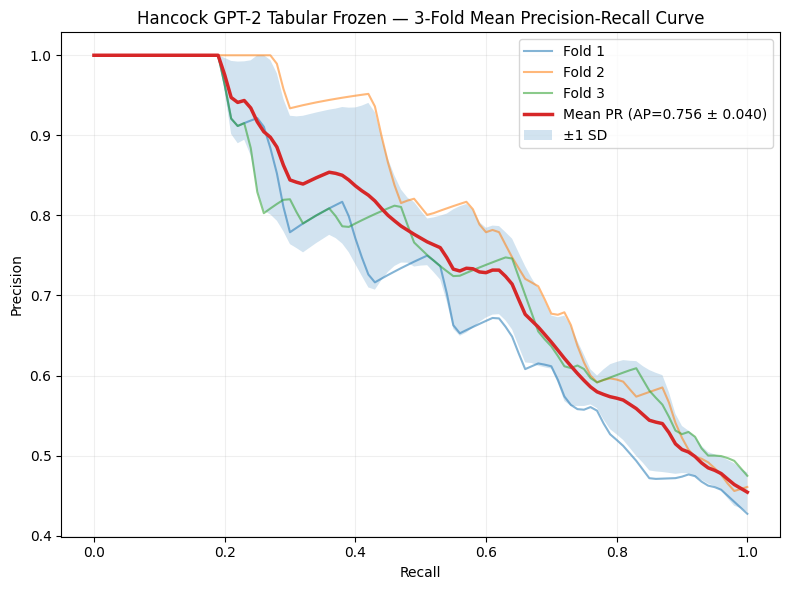


HANCOCK GPT-2 TABULAR 3-FOLD CV COMPLETED

Number of folds: 3
Total validation predictions: 332
Unique patients evaluated: 332
Patients evaluated exactly once: True

NO TEST SET WAS CREATED.
NO TEST METRICS WERE CALCULATED.

All outputs saved to:
/content/drive/MyDrive/GPT2_Tabular_Hancock_Frozen_3Fold_CV

Saved files:
Hancock_3Fold_All_Validation_Predictions.csv
Hancock_3Fold_Fold_Level_Metrics.csv
Hancock_3Fold_Mean_PR_coordinates.csv
Hancock_3Fold_Mean_ROC_coordinates.csv
Hancock_3Fold_Mean_Standard_Deviation.csv
Hancock_3Fold_Run_Summary.json
Hancock_GPT2_Tabular_Frozen_3Fold_Mean_PR.png
Hancock_GPT2_Tabular_Frozen_3Fold_Mean_ROC.png
checkpoints
fold_1_PR_coordinates.csv
fold_1_ROC_coordinates.csv
fold_1_training_history.csv
fold_1_validation_predictions.csv
fold_2_PR_coordinates.csv
fold_2_ROC_coordinates.csv
fold_2_training_history.csv
fold_2_validation_predictions.csv
fold_3_PR_coordinates.csv
fold_3_ROC_coordinates.csv
fold_3_training_history.csv
fold_3_validation_predictions.

In [4]:

# ============================================================
# HANCOCK HPV — GPT-2 TABULAR CLASSIFIER
# FULLY FROZEN GPT-2 — STRATIFIED 3-FOLD CROSS-VALIDATION
#
# Same architecture and training settings as the held-out
# GPT-2 Tabular experiment.
#
# NO TEST SET
# NO TEST PREDICTIONS
# NO TEST METRICS
#
# Each fold:
#   Train on 2 folds
#   Validate on 1 fold
#   Select checkpoint using validation ROC-AUC
#   Select threshold using validation balanced accuracy
#
# Final:
#   Individual fold ROC and PR curves
#   Mean ROC and PR curves with +/- 1 SD bands
# ============================================================

import os
import json
import random
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from google.colab import drive
from transformers import GPT2Model

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore", category=FutureWarning)

# ============================================================
# 1. SETTINGS
# ============================================================

SEED = 42
N_SPLITS = 3

MAX_EPOCHS = 500
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1

MODEL_NAME = "openai-community/gpt2"

BASE = "/content/drive/MyDrive"

OUT_DIR = os.path.join(
    BASE,
    "GPT2_Tabular_Hancock_Frozen_3Fold_CV"
)

CHECKPOINT_DIR = os.path.join(
    OUT_DIR,
    "checkpoints"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

drive.mount("/content/drive")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Output folder:", OUT_DIR)


def seed_everything(seed=42):

    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False

        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

    torch.use_deterministic_algorithms(
        True,
        warn_only=True
    )


seed_everything(SEED)

# ============================================================
# 2. LOAD AND PREPARE HANCOCK DATA
# ============================================================

def load_json_table(path):

    with open(path, encoding="utf-8") as f:
        obj = json.load(f)

    if isinstance(obj, list):
        return pd.DataFrame(obj)

    if isinstance(obj, dict):

        for key in [
            "data",
            "records",
            "patients",
            "items"
        ]:

            if isinstance(obj.get(key), list):
                return pd.DataFrame(obj[key])

        return pd.DataFrame(obj)

    raise ValueError(f"Cannot read table: {path}")


clinical = load_json_table(
    os.path.join(BASE, "clinical_data.json")
)

pathology = load_json_table(
    os.path.join(BASE, "pathological_data.json")
)

if "patient_id" not in clinical.columns:
    raise KeyError(
        "clinical_data.json must contain patient_id."
    )

if "patient_id" not in pathology.columns:
    raise KeyError(
        "pathological_data.json must contain patient_id."
    )

df = clinical.merge(
    pathology,
    on="patient_id",
    how="left",
    suffixes=("", "_path")
)

target_col = next(
    (
        c for c in [
            "hpv_association_p16",
            "hpv_association_p16_path"
        ]
        if c in df.columns
    ),
    None
)

if target_col is None:
    raise KeyError(
        "Could not find hpv_association_p16 target."
    )


feature_candidates = {

    "age_at_initial_diagnosis": [
        "age_at_initial_diagnosis"
    ],

    "sex": [
        "sex"
    ],

    "smoking_status": [
        "smoking_status"
    ],

    "primary_tumor_site": [
        "primary_tumor_site"
    ],

    "primarily_metastasis": [
        "primarily_metastasis"
    ],

    "pN_stage": [
        "pN_stage",
        "pN_stage_path",
        "pathological_N_stage",
        "pathological_n_stage"
    ]
}


rename_map = {}

for feature, candidates in feature_candidates.items():

    found = next(
        (
            c for c in candidates
            if c in df.columns
        ),
        None
    )

    if found is None:
        raise KeyError(
            f"Missing predictor {feature}; "
            f"checked {candidates}"
        )

    if found != feature:
        rename_map[found] = feature


df = df.rename(columns=rename_map)

features = list(feature_candidates)


def normalize_label(value):

    if pd.isna(value):
        return np.nan

    value = str(value).strip().lower()

    if value in {
        "negative", "neg", "0", "false", "no"
    }:
        return 0

    if value in {
        "positive", "pos", "1", "true", "yes"
    }:
        return 1

    try:

        number = float(value)

        if number in (0.0, 1.0):
            return int(number)

    except (ValueError, TypeError):
        pass

    return np.nan


df["HPV_Label"] = df[target_col].map(
    normalize_label
)

df = df.dropna(
    subset=["HPV_Label"]
).copy()

df["HPV_Label"] = df["HPV_Label"].astype(int)

df = df[
    ["patient_id"] + features + ["HPV_Label"]
].copy()

df = df.reset_index(drop=True)

print("\nFull Hancock dataset:")
print("Patients:", len(df))

print(
    "Class counts:",
    df["HPV_Label"].value_counts().sort_index().to_dict()
)

print("\nFeatures:")
print(features)

assert len(df) == 332, (
    f"Expected 332 patients, found {len(df)}. "
    "Check the data files and target preparation."
)

assert df["patient_id"].nunique() == 332

# ============================================================
# 3. STRATIFIED 3-FOLD SPLITTING
# ============================================================

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

X_all = df[features]
y_all = df["HPV_Label"].to_numpy(dtype=np.int64)

fold_splits = list(
    skf.split(X_all, y_all)
)

print("\n3-fold split verification:")

for fold, (train_idx, val_idx) in enumerate(
    fold_splits, start=1
):

    y_train_fold = y_all[train_idx]
    y_val_fold = y_all[val_idx]

    print(f"\nFold {fold}")

    print(
        "Training:",
        len(train_idx),
        "Class counts:",
        np.bincount(y_train_fold, minlength=2).tolist()
    )

    print(
        "Validation:",
        len(val_idx),
        "Class counts:",
        np.bincount(y_val_fold, minlength=2).tolist()
    )

    assert len(set(train_idx).intersection(set(val_idx))) == 0


# ============================================================
# 4. TABULAR GPT-2 ARCHITECTURE
# SAME AS HELD-OUT NOTEBOOK
# ============================================================

class GPT2TabularClassifier(nn.Module):

    def __init__(self, n_features, dropout=0.1):

        super().__init__()

        self.gpt2 = GPT2Model.from_pretrained(
            MODEL_NAME
        )

        # Freeze the complete GPT-2 backbone
        for param in self.gpt2.parameters():
            param.requires_grad = False

        hidden = self.gpt2.config.hidden_size

        self.feature_projection = nn.Linear(
            1,
            hidden
        )

        self.feature_embedding = nn.Parameter(
            torch.zeros(1, n_features, hidden)
        )

        nn.init.normal_(
            self.feature_embedding,
            mean=0.0,
            std=0.02
        )

        self.classifier = nn.Sequential(

            nn.LayerNorm(hidden),

            nn.Dropout(dropout),

            nn.Linear(hidden, 128),

            nn.GELU(),

            nn.Dropout(dropout),

            nn.Linear(128, 2)
        )


    def forward(self, x):

        tokens = self.feature_projection(
            x.unsqueeze(-1)
        )

        tokens = tokens + self.feature_embedding

        hidden = self.gpt2(
            inputs_embeds=tokens
        ).last_hidden_state

        return self.classifier(
            hidden.mean(dim=1)
        )


# ============================================================
# 5. PREPROCESSING FUNCTION
# FIT ONLY ON THE TRAINING PORTION OF EACH FOLD
# ============================================================

numeric_features = [
    "age_at_initial_diagnosis"
]

categorical_features = [
    c for c in features
    if c not in numeric_features
]


def prepare_fold_data(train_df, val_df):

    X_train_df = train_df[features].copy()
    X_val_df = val_df[features].copy()

    for frame in [X_train_df, X_val_df]:

        frame["age_at_initial_diagnosis"] = pd.to_numeric(
            frame["age_at_initial_diagnosis"],
            errors="coerce"
        )

    age_median = X_train_df[
        "age_at_initial_diagnosis"
    ].median()

    if pd.isna(age_median):
        age_median = 0.0

    for frame in [X_train_df, X_val_df]:

        frame["age_at_initial_diagnosis"] = (
            frame["age_at_initial_diagnosis"].fillna(
                age_median
            )
        )

    for col in categorical_features:

        modes = (
            X_train_df[col]
            .dropna()
            .astype(str)
            .mode()
        )

        fill_value = (
            modes.iloc[0]
            if not modes.empty
            else "Unknown"
        )

        for frame in [X_train_df, X_val_df]:

            frame[col] = frame[col].fillna(
                fill_value
            )

            frame[col] = (
                frame[col]
                .astype(str)
                .replace({
                    "": "Unknown",
                    "nan": "Unknown",
                    "None": "Unknown"
                })
            )

    try:

        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )

    except TypeError:

        encoder = OneHotEncoder(
            handle_unknown="ignore",
            sparse=False
        )

    preprocessor = ColumnTransformer([

        (
            "num",
            StandardScaler(),
            numeric_features
        ),

        (
            "cat",
            encoder,
            categorical_features
        )

    ])

    X_train = preprocessor.fit_transform(
        X_train_df
    ).astype(np.float32)

    X_val = preprocessor.transform(
        X_val_df
    ).astype(np.float32)

    return X_train, X_val, preprocessor


# ============================================================
# 6. THRESHOLD SELECTION
# SAME AS HELD-OUT NOTEBOOK
# ============================================================

def select_threshold(y_true, probabilities):

    thresholds = np.unique(
        np.concatenate((
            [0.0],
            probabilities,
            [1.0]
        ))
    )

    results = [

        (
            float(t),

            balanced_accuracy_score(
                y_true,
                (probabilities >= t).astype(int)
            )
        )

        for t in thresholds
    ]

    # Maximise balanced accuracy;
    # ties closest to 0.5
    return max(
        results,
        key=lambda x: (
            x[1],
            -abs(x[0] - 0.5)
        )
    )


# ============================================================
# 7. TRAINING AND PREDICTION FUNCTIONS
# ============================================================

def weighted_classification_loss(
    logits,
    labels,
    class_weights
):

    losses = nn.functional.cross_entropy(
        logits,
        labels,
        reduction="none"
    )

    return (
        losses * class_weights[labels]
    ).mean()


def predict_probabilities(model, X_tensor):

    model.eval()

    with torch.no_grad():

        probabilities = torch.softmax(
            model(X_tensor),
            dim=1
        )[:, 1]

    return probabilities.cpu().numpy()


def evaluate_validation_loss(
    model,
    X_val_tensor,
    y_val_tensor,
    class_weights
):

    model.eval()

    with torch.no_grad():

        logits = model(X_val_tensor)

        loss = weighted_classification_loss(
            logits,
            y_val_tensor,
            class_weights
        )

    return float(loss.item())


# ============================================================
# 8. STORAGE FOR FOLD RESULTS
# ============================================================

fold_metrics = []

fold_predictions = []

fold_roc_curves = []

fold_pr_curves = []

fold_histories = []

# Common interpolation grids
mean_fpr = np.linspace(0, 1, 101)

mean_recall = np.linspace(0, 1, 101)

# ============================================================
# 9. RUN THREE FOLDS
# ============================================================

for fold_number, (train_idx, val_idx) in enumerate(
    fold_splits,
    start=1
):

    print("\n" + "=" * 70)
    print(f"STARTING FOLD {fold_number}/{N_SPLITS}")
    print("=" * 70)

    # Reproducible but fold-specific initialisation
    seed_everything(SEED + fold_number)

    # --------------------------------------------------------
    # 9A. SPLIT DATA
    # --------------------------------------------------------

    train_df = df.iloc[train_idx].copy()
    val_df = df.iloc[val_idx].copy()

    train_df = train_df.reset_index(drop=True)
    val_df = val_df.reset_index(drop=True)

    y_train = train_df[
        "HPV_Label"
    ].to_numpy(dtype=np.int64)

    y_val = val_df[
        "HPV_Label"
    ].to_numpy(dtype=np.int64)

    print("Training patients:", len(train_df))
    print("Validation patients:", len(val_df))

    # --------------------------------------------------------
    # 9B. PREPROCESSING
    # --------------------------------------------------------

    X_train, X_val, preprocessor = prepare_fold_data(
        train_df,
        val_df
    )

    print(
        "Encoded feature dimension:",
        X_train.shape[1]
    )

    # --------------------------------------------------------
    # 9C. CLASS WEIGHTS
    # Calculated from training fold only
    # --------------------------------------------------------

    counts = np.bincount(
        y_train,
        minlength=2
    )

    if np.any(counts == 0):
        raise ValueError(
            f"Fold {fold_number}: missing class in training."
        )

    weights = len(y_train) / (2.0 * counts)

    class_weights = torch.tensor(
        weights,
        dtype=torch.float32,
        device=device
    )

    print("Training class weights:", weights)

    # --------------------------------------------------------
    # 9D. DATA LOADERS
    # --------------------------------------------------------

    train_dataset = TensorDataset(

        torch.tensor(
            X_train,
            dtype=torch.float32
        ),

        torch.tensor(
            y_train,
            dtype=torch.long
        )
    )

    train_loader = DataLoader(

        train_dataset,

        batch_size=BATCH_SIZE,

        shuffle=True,

        generator=torch.Generator().manual_seed(
            SEED + fold_number
        )
    )

    X_val_tensor = torch.tensor(
        X_val,
        dtype=torch.float32,
        device=device
    )

    y_val_tensor = torch.tensor(
        y_val,
        dtype=torch.long,
        device=device
    )

    # --------------------------------------------------------
    # 9E. INITIALISE MODEL
    # --------------------------------------------------------

    model = GPT2TabularClassifier(
        n_features=X_train.shape[1],
        dropout=DROPOUT
    ).to(device)

    gpt2_trainable = sum(
        p.numel()
        for p in model.gpt2.parameters()
        if p.requires_grad
    )

    other_trainable = sum(
        p.numel()
        for name, p in model.named_parameters()
        if not name.startswith("gpt2.")
        and p.requires_grad
    )

    print(
        "GPT-2 trainable parameters:",
        gpt2_trainable
    )

    print(
        "Other trainable parameters:",
        other_trainable
    )

    assert gpt2_trainable == 0
    assert other_trainable > 0

    # --------------------------------------------------------
    # 9F. OPTIMIZER
    # --------------------------------------------------------

    optimizer = torch.optim.AdamW(

        filter(
            lambda p: p.requires_grad,
            model.parameters()
        ),

        lr=LEARNING_RATE,

        weight_decay=WEIGHT_DECAY
    )

    # --------------------------------------------------------
    # 9G. CHECKPOINT SELECTION
    # Best validation ROC-AUC
    # --------------------------------------------------------

    best_val_roc_auc = -float("inf")

    best_epoch = None

    best_checkpoint = None

    history = []

    fold_checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"fold_{fold_number}_best_val_roc_auc.pt"
    )

    # --------------------------------------------------------
    # 9H. TRAIN FOR 500 EPOCHS
    # --------------------------------------------------------

    for epoch in range(1, MAX_EPOCHS + 1):

        model.train()

        # Keep the frozen GPT-2 backbone in evaluation mode
        model.gpt2.eval()

        loss_sum = 0.0

        n_seen = 0

        for xb, yb in train_loader:

            xb = xb.to(device)

            yb = yb.to(device)

            optimizer.zero_grad()

            logits = model(xb)

            loss = weighted_classification_loss(
                logits,
                yb,
                class_weights
            )

            loss.backward()

            optimizer.step()

            loss_sum += loss.item() * len(yb)

            n_seen += len(yb)

        train_loss = loss_sum / max(n_seen, 1)

        # Validation loss
        val_loss = evaluate_validation_loss(
            model,
            X_val_tensor,
            y_val_tensor,
            class_weights
        )

        # Validation predictions
        val_prob = predict_probabilities(
            model,
            X_val_tensor
        )

        # Validation metrics
        val_roc_auc = roc_auc_score(
            y_val,
            val_prob
        )

        val_pr_auc = average_precision_score(
            y_val,
            val_prob
        )

        val_threshold, val_bal_acc = select_threshold(
            y_val,
            val_prob
        )

        history.append({

            "fold": fold_number,

            "epoch": epoch,

            "train_loss": train_loss,

            "val_loss": val_loss,

            "val_roc_auc": val_roc_auc,

            "val_pr_auc": val_pr_auc,

            "val_balanced_accuracy": val_bal_acc,

            "val_threshold": val_threshold

        })

        # Select best checkpoint using validation ROC-AUC
        if val_roc_auc > best_val_roc_auc:

            best_val_roc_auc = float(val_roc_auc)

            best_epoch = epoch

            best_checkpoint = {

                "fold": fold_number,

                "epoch": epoch,

                "model_state_dict": copy.deepcopy(
                    model.state_dict()
                ),

                "validation_loss": float(val_loss),

                "validation_roc_auc": float(
                    val_roc_auc
                ),

                "validation_pr_auc": float(
                    val_pr_auc
                ),

                "validation_balanced_accuracy": float(
                    val_bal_acc
                ),

                "validation_threshold": float(
                    val_threshold
                )

            }

            torch.save(
                best_checkpoint,
                fold_checkpoint_path
            )

        if epoch % 50 == 0:

            print(
                f"Fold {fold_number} | "
                f"Epoch {epoch}/{MAX_EPOCHS} | "
                f"Train loss={train_loss:.4f} | "
                f"Val loss={val_loss:.4f} | "
                f"ROC-AUC={val_roc_auc:.4f} | "
                f"PR-AUC={val_pr_auc:.4f} | "
                f"BA={val_bal_acc:.4f}"
            )

    # --------------------------------------------------------
    # 9I. SAVE TRAINING HISTORY
    # --------------------------------------------------------

    history_df = pd.DataFrame(history)

    history_df.to_csv(
        os.path.join(
            OUT_DIR,
            f"fold_{fold_number}_training_history.csv"
        ),
        index=False
    )

    fold_histories.append(history_df)

    print(
        f"\nFold {fold_number} best epoch:",
        best_epoch
    )

    print(
        "Best validation ROC-AUC:",
        round(best_val_roc_auc, 4)
    )

    # --------------------------------------------------------
    # 9J. RESTORE BEST CHECKPOINT
    # --------------------------------------------------------

    saved_checkpoint = torch.load(
        fold_checkpoint_path,
        map_location=device,
        weights_only=False
    )

    model.load_state_dict(
        saved_checkpoint["model_state_dict"]
    )

    # Validation predictions from selected checkpoint
    val_prob = predict_probabilities(
        model,
        X_val_tensor
    )

    # Threshold selected from this validation fold
    threshold, threshold_ba = select_threshold(
        y_val,
        val_prob
    )

    val_pred = (
        val_prob >= threshold
    ).astype(int)

    # --------------------------------------------------------
    # 9K. VALIDATION METRICS
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        val_pred,
        labels=[0, 1]
    ).ravel()

    fold_result = {

        "Fold": fold_number,

        "Training_N": len(train_df),

        "Validation_N": len(val_df),

        "Selected_Epoch": best_epoch,

        "Threshold": threshold,

        "Validation_Loss": saved_checkpoint[
            "validation_loss"
        ],

        "ROC_AUC": roc_auc_score(
            y_val,
            val_prob
        ),

        "PR_AUC": average_precision_score(
            y_val,
            val_prob
        ),

        "Balanced_Accuracy": balanced_accuracy_score(
            y_val,
            val_pred
        ),

        "Sensitivity": recall_score(
            y_val,
            val_pred,
            pos_label=1,
            zero_division=0
        ),

        "Specificity": (
            tn / (tn + fp)
            if (tn + fp) > 0
            else np.nan
        ),

        "F1": f1_score(
            y_val,
            val_pred,
            zero_division=0
        ),

        "TN": tn,

        "FP": fp,

        "FN": fn,

        "TP": tp

    }

    fold_metrics.append(fold_result)

    print("\nFold metrics:")

    print(
        pd.Series(fold_result).to_string()
    )

    # --------------------------------------------------------
    # 9L. SAVE FOLD VALIDATION PREDICTIONS
    # --------------------------------------------------------

    prediction_df = pd.DataFrame({

        "patient_id": val_df[
            "patient_id"
        ].to_numpy(),

        "y_true": y_val,

        "probability_positive": val_prob,

        "prediction": val_pred,

        "fold": fold_number,

        "selected_epoch": best_epoch,

        "threshold": threshold

    })

    prediction_df.to_csv(
        os.path.join(
            OUT_DIR,
            f"fold_{fold_number}_validation_predictions.csv"
        ),
        index=False
    )

    fold_predictions.append(prediction_df)

    # --------------------------------------------------------
    # 9M. ROC COORDINATES
    # --------------------------------------------------------

    fpr, tpr, _ = roc_curve(
        y_val,
        val_prob
    )

    roc_auc = roc_auc_score(
        y_val,
        val_prob
    )

    roc_df = pd.DataFrame({

        "FPR": fpr,

        "TPR": tpr

    })

    roc_df.to_csv(
        os.path.join(
            OUT_DIR,
            f"fold_{fold_number}_ROC_coordinates.csv"
        ),
        index=False
    )

    # Interpolate for mean ROC curve
    interp_tpr = np.interp(
        mean_fpr,
        fpr,
        tpr
    )

    interp_tpr[0] = 0.0

    fold_roc_curves.append(interp_tpr)

    # --------------------------------------------------------
    # 9N. PRECISION-RECALL COORDINATES
    # --------------------------------------------------------

    precision, recall, _ = precision_recall_curve(
        y_val,
        val_prob
    )

    pr_auc = average_precision_score(
        y_val,
        val_prob
    )

    pr_df = pd.DataFrame({

        "Recall": recall,

        "Precision": precision

    })

    pr_df.to_csv(
        os.path.join(
            OUT_DIR,
            f"fold_{fold_number}_PR_coordinates.csv"
        ),
        index=False
    )

    # Interpolate PR curve for mean PR curve
    # Recall is reversed into increasing order
    recall_ascending = recall[::-1]

    precision_ascending = precision[::-1]

    unique_recall, unique_indices = np.unique(
        recall_ascending,
        return_index=True
    )

    unique_precision = precision_ascending[
        unique_indices
    ]

    interp_precision = np.interp(
        mean_recall,
        unique_recall,
        unique_precision
    )

    fold_pr_curves.append(
        interp_precision
    )

    # --------------------------------------------------------
    # 9O. CLEAN UP BEFORE NEXT FOLD
    # --------------------------------------------------------

    del model
    del optimizer
    del train_loader
    del X_val_tensor
    del y_val_tensor

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# 10. SAVE FOLD-LEVEL METRICS AND SUMMARY
# ============================================================

metrics_df = pd.DataFrame(fold_metrics)

metrics_df.to_csv(
    os.path.join(
        OUT_DIR,
        "Hancock_3Fold_Fold_Level_Metrics.csv"
    ),
    index=False
)

summary_rows = []

metric_columns = [

    "ROC_AUC",

    "PR_AUC",

    "Balanced_Accuracy",

    "Sensitivity",

    "Specificity",

    "F1"

]

for metric in metric_columns:

    summary_rows.append({

        "Metric": metric,

        "Mean": metrics_df[metric].mean(),

        "Standard_Deviation": metrics_df[
            metric
        ].std(ddof=1)

    })

summary_df = pd.DataFrame(summary_rows)

summary_df.to_csv(
    os.path.join(
        OUT_DIR,
        "Hancock_3Fold_Mean_Standard_Deviation.csv"
    ),
    index=False
)

# Save all validation predictions together
# Each patient should appear exactly once
all_predictions_df = pd.concat(
    fold_predictions,
    ignore_index=True
)

all_predictions_df.to_csv(
    os.path.join(
        OUT_DIR,
        "Hancock_3Fold_All_Validation_Predictions.csv"
    ),
    index=False
)

assert len(all_predictions_df) == 332

assert (
    all_predictions_df["patient_id"].nunique()
    == 332
)

assert (
    all_predictions_df["fold"].value_counts().sort_index().shape[0]
    == 3
)

print("\nFOLD-LEVEL METRICS")
display(metrics_df.round(4))

print("\nMEAN AND STANDARD DEVIATION")
display(summary_df.round(4))


# ============================================================
# 11. MEAN ROC CURVE WITH +/- 1 SD BAND
# ============================================================

roc_array = np.vstack(
    fold_roc_curves
)

mean_tpr = np.mean(
    roc_array,
    axis=0
)

std_tpr = np.std(
    roc_array,
    axis=0,
    ddof=1
)

mean_tpr[-1] = 1.0

mean_auc = metrics_df["ROC_AUC"].mean()

std_auc = metrics_df["ROC_AUC"].std(
    ddof=1
)

plt.figure(figsize=(8, 6))

for i, tpr in enumerate(
    fold_roc_curves,
    start=1
):

    plt.plot(
        mean_fpr,
        tpr,
        alpha=0.55,
        label=f"Fold {i}"
    )

plt.plot(
    mean_fpr,
    mean_tpr,
    linewidth=2.5,
    label=(
        f"Mean ROC "
        f"(AUC={mean_auc:.3f} ± {std_auc:.3f})"
    )
)

lower = np.maximum(
    mean_tpr - std_tpr,
    0
)

upper = np.minimum(
    mean_tpr + std_tpr,
    1
)

plt.fill_between(
    mean_fpr,
    lower,
    upper,
    alpha=0.2,
    label="±1 SD"
)

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Chance"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title(
    "Hancock GPT-2 Tabular Frozen — "
    "3-Fold Mean ROC Curve"
)

plt.legend(loc="lower right")

plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUT_DIR,
        "Hancock_GPT2_Tabular_Frozen_3Fold_Mean_ROC.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Save mean ROC coordinates
pd.DataFrame({

    "FPR": mean_fpr,

    "Mean_TPR": mean_tpr,

    "Lower_1SD": lower,

    "Upper_1SD": upper

}).to_csv(
    os.path.join(
        OUT_DIR,
        "Hancock_3Fold_Mean_ROC_coordinates.csv"
    ),
    index=False
)


# ============================================================
# 12. MEAN PR CURVE WITH +/- 1 SD BAND
# ============================================================

pr_array = np.vstack(
    fold_pr_curves
)

mean_precision = np.mean(
    pr_array,
    axis=0
)

std_precision = np.std(
    pr_array,
    axis=0,
    ddof=1
)

mean_ap = metrics_df["PR_AUC"].mean()

std_ap = metrics_df["PR_AUC"].std(
    ddof=1
)

plt.figure(figsize=(8, 6))

for i, precision_curve in enumerate(
    fold_pr_curves,
    start=1
):

    plt.plot(
        mean_recall,
        precision_curve,
        alpha=0.55,
        label=f"Fold {i}"
    )

plt.plot(
    mean_recall,
    mean_precision,
    linewidth=2.5,
    label=(
        f"Mean PR "
        f"(AP={mean_ap:.3f} ± {std_ap:.3f})"
    )
)

lower = np.maximum(
    mean_precision - std_precision,
    0
)

upper = np.minimum(
    mean_precision + std_precision,
    1
)

plt.fill_between(
    mean_recall,
    lower,
    upper,
    alpha=0.2,
    label="±1 SD"
)

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.title(
    "Hancock GPT-2 Tabular Frozen — "
    "3-Fold Mean Precision-Recall Curve"
)

plt.legend(loc="best")

plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUT_DIR,
        "Hancock_GPT2_Tabular_Frozen_3Fold_Mean_PR.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Save mean PR coordinates
pd.DataFrame({

    "Recall": mean_recall,

    "Mean_Precision": mean_precision,

    "Lower_1SD": lower,

    "Upper_1SD": upper

}).to_csv(
    os.path.join(
        OUT_DIR,
        "Hancock_3Fold_Mean_PR_coordinates.csv"
    ),
    index=False
)


# ============================================================
# 13. SAVE RUN SUMMARY
# ============================================================

run_summary = {

    "dataset": "Hancock",

    "total_patients": int(len(df)),

    "positive_patients": int(
        (y_all == 1).sum()
    ),

    "negative_patients": int(
        (y_all == 0).sum()
    ),

    "model": "GPT2_Tabular_Fully_Frozen",

    "model_name": MODEL_NAME,

    "gpt2_backbone_frozen": True,

    "folds": N_SPLITS,

    "random_seed": SEED,

    "epochs": MAX_EPOCHS,

    "batch_size": BATCH_SIZE,

    "learning_rate": LEARNING_RATE,

    "weight_decay": WEIGHT_DECAY,

    "dropout": DROPOUT,

    "smote": False,

    "test_set": False,

    "test_metrics": False,

    "checkpoint_selection": "Best validation ROC-AUC",

    "threshold_selection": (
        "Maximum validation balanced accuracy; "
        "ties closest to 0.5"
    ),

    "preprocessing": (
        "Fit independently on each fold's training data"
    ),

    "evaluation": (
        "Each fold's validation predictions and metrics "
        "are evaluated separately"
    ),

    "curve_aggregation": (
        "Mean interpolated fold curves with +/- 1 SD band"
    ),

    "features": features

}

with open(
    os.path.join(
        OUT_DIR,
        "Hancock_3Fold_Run_Summary.json"
    ),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        run_summary,
        f,
        indent=2
    )


# ============================================================
# 14. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 70)

print("HANCOCK GPT-2 TABULAR 3-FOLD CV COMPLETED")

print("=" * 70)

print("\nNumber of folds:", N_SPLITS)

print(
    "Total validation predictions:",
    len(all_predictions_df)
)

print(
    "Unique patients evaluated:",
    all_predictions_df["patient_id"].nunique()
)

print(
    "Patients evaluated exactly once:",
    (
        all_predictions_df.groupby("patient_id")[
            "fold"
        ].nunique().eq(1).all()
    )
)

print("\nNO TEST SET WAS CREATED.")

print("NO TEST METRICS WERE CALCULATED.")

print("\nAll outputs saved to:")

print(OUT_DIR)

print("\nSaved files:")

for filename in sorted(os.listdir(OUT_DIR)):

    print(filename)
